In [14]:
import numpy as np
import os
import sys
from tqdm import tqdm
import arviz as az

import matplotlib.pyplot as plt
import matplotlib

from scipy.ndimage import gaussian_filter

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *
from GLOBAL.mcmc import *

directory = 'chain'
prefix = 'chain_'

PARAM_CHAINS = []
ESS_total = 0
chunk_files = [file for file in os.listdir(directory) if file.startswith(prefix) and file.endswith('.npz')]
N_PARTICLES_L = []
MUTATION_L = []
ESS_L = []
ACCEPTANCE_L = []
LENGTH_L = []
for file in chunk_files:
    data = np.load(os.path.join(directory, file))
    CHAINS = data['CHAINS']
    acceptance_rate = data['acceptance']
    mutation_rate = data['mutation_rate']
    n_particles = data['particle_count']
    mutation = data['mutation_rate']
    n_samples, n_params = CHAINS.shape
    LENGTH_L.append(n_samples)
    ESS = [az.ess(CHAINS[:, i]) for i in range(n_params)]
    ESS_total += min(ESS)
    print(n_particles, "particles, mutation rate", mutation, "with", n_samples, "samples and", n_params, "parameters. Min ESS:", min(ESS))
    PARAM_CHAINS.append(CHAINS)
    N_PARTICLES_L.append(n_particles)
    MUTATION_L.append(mutation)
    ESS_L.append(min(ESS))
    ACCEPTANCE_L.append(acceptance_rate)
    
print("Total ESS:", ESS_total)

# Sort N_PARTICLES and ESS by N_PARTICLES
# ESS_L = [ess for n, ess in sorted(zip(N_PARTICLES_L, ESS_L))]

2500 particles, mutation rate 0.0003 with 321 samples and 3 parameters. Min ESS: 2.40800009716433
2500 particles, mutation rate 0.004 with 165 samples and 3 parameters. Min ESS: 2.081409182133817
2500 particles, mutation rate 3.0 with 204 samples and 3 parameters. Min ESS: 12.695929151085894
2500 particles, mutation rate 0.009 with 153 samples and 3 parameters. Min ESS: 2.036492083349754
2500 particles, mutation rate 0.8 with 171 samples and 3 parameters. Min ESS: 2.7311607051487434
2500 particles, mutation rate 0.003 with 165 samples and 3 parameters. Min ESS: 2.4089815757579247
2500 particles, mutation rate 3.0 with 165 samples and 3 parameters. Min ESS: 3.9683214036508416
2500 particles, mutation rate 0.004 with 210 samples and 3 parameters. Min ESS: 5.769630964452266
2500 particles, mutation rate 6.0 with 174 samples and 3 parameters. Min ESS: 4.88033878301844
2500 particles, mutation rate 0.0009 with 171 samples and 3 parameters. Min ESS: 2.3992228828311712
2500 particles, mutatio

Text(0, 0.5, 'Effective Sample Size')

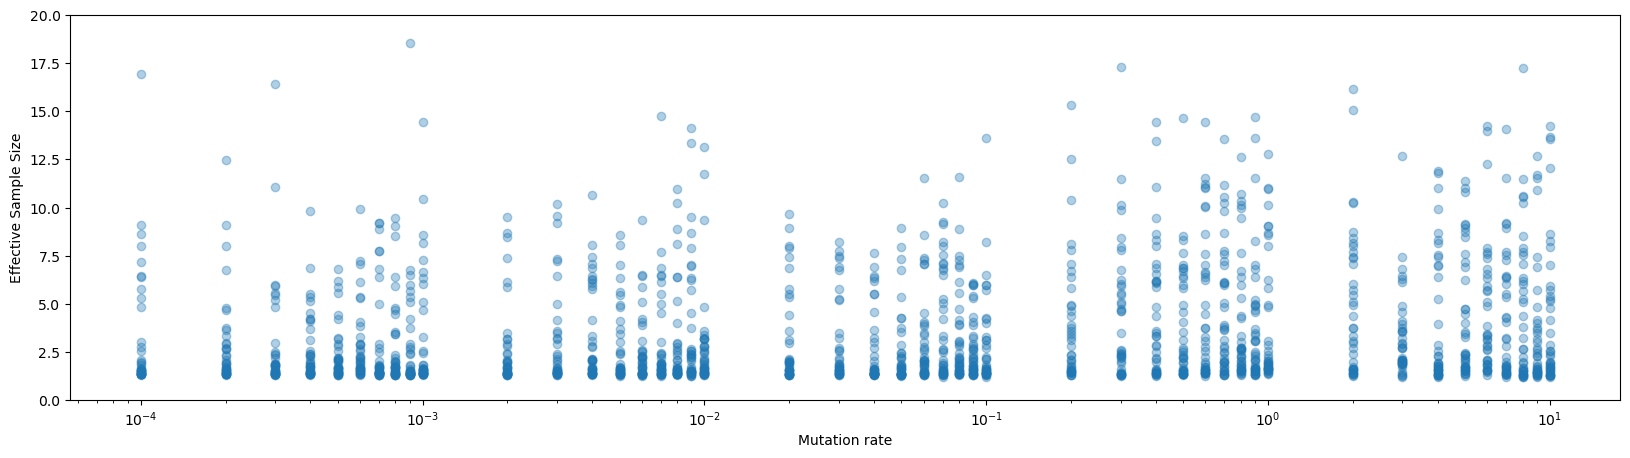

In [15]:
plt.figure(figsize=(20, 5))
plt.semilogx(MUTATION_L, np.array(ESS_L), 'o', alpha=0.35)
plt.ylim(0, 20)
plt.xlabel('Mutation rate')
plt.ylabel('Effective Sample Size')

Text(0, 0.5, 'Sample Size')

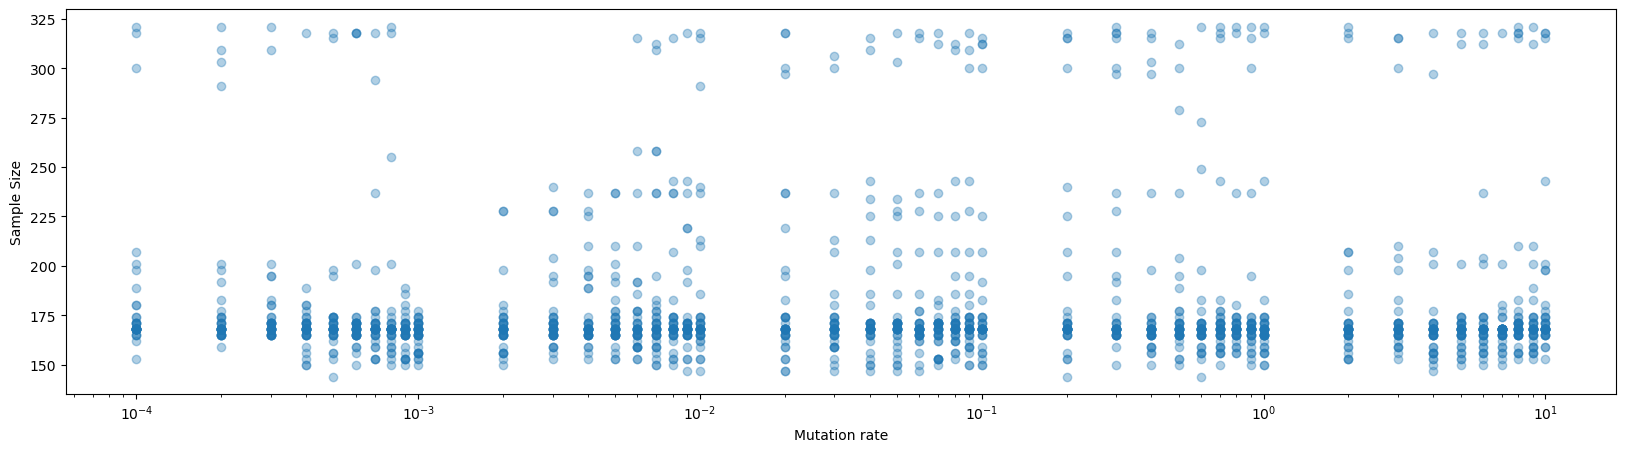

In [20]:
plt.figure(figsize=(20, 5))
plt.semilogx(MUTATION_L, LENGTH_L, 'o', alpha=0.35)
plt.xlabel('Mutation rate')
plt.ylabel('Sample Size')

Text(0, 0.5, 'Sample Size')

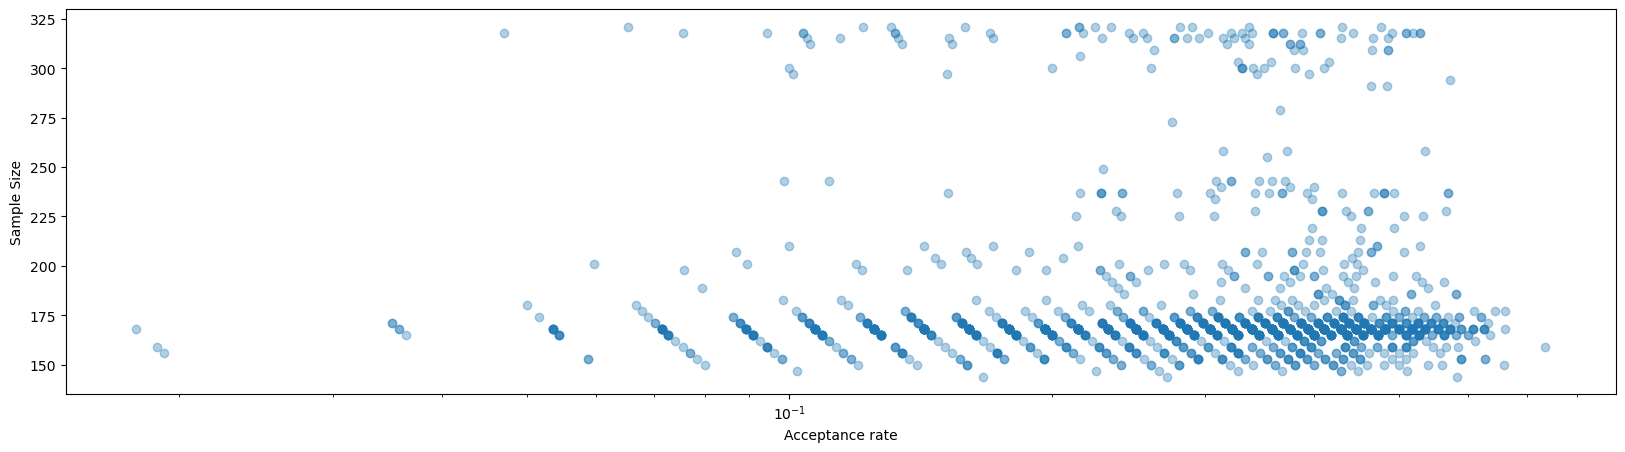

In [21]:
plt.figure(figsize=(20, 5))
plt.semilogx(ACCEPTANCE_L, LENGTH_L, 'o', alpha=0.35)
plt.xlabel('Acceptance rate')
plt.ylabel('Sample Size')

Text(0, 0.5, 'Acceptance rate')

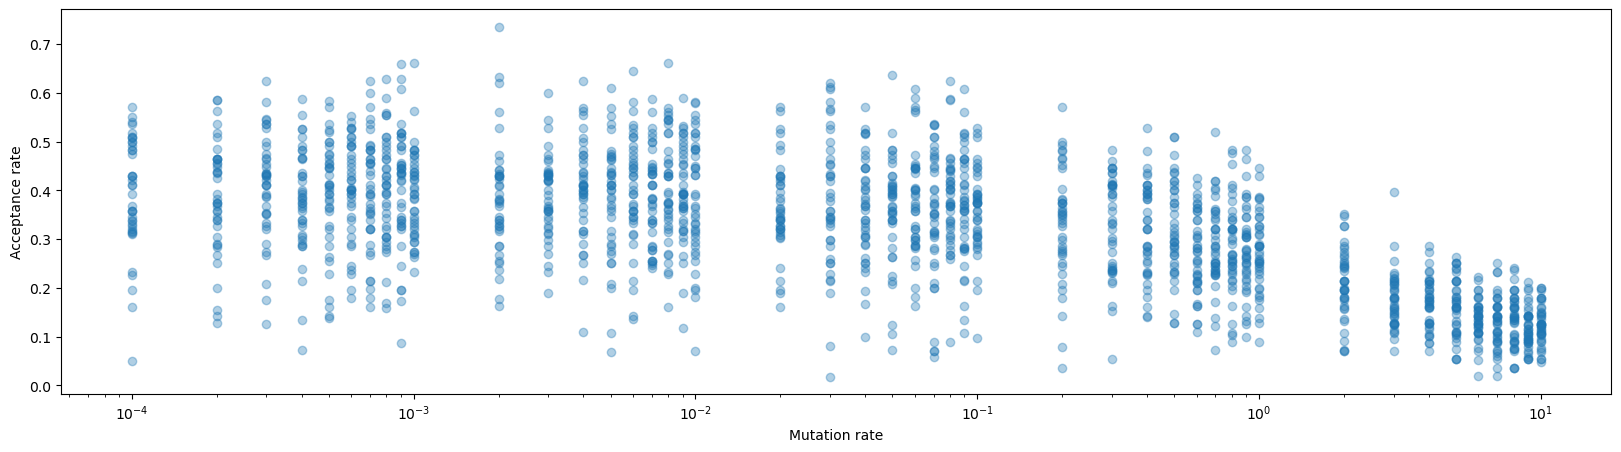

In [22]:
plt.figure(figsize=(20, 5))
plt.semilogx(MUTATION_L, ACCEPTANCE_L, 'o', alpha=0.35)
plt.xlabel('Mutation rate')
plt.ylabel('Acceptance rate')

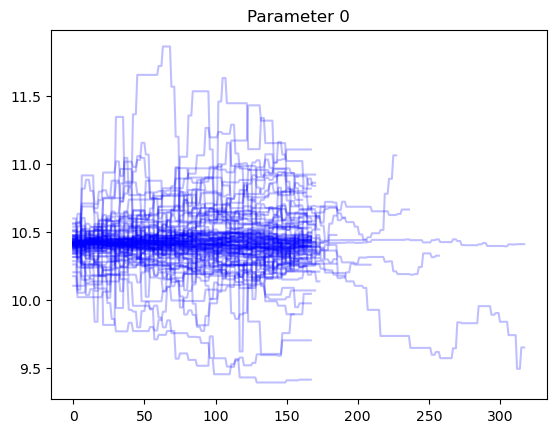

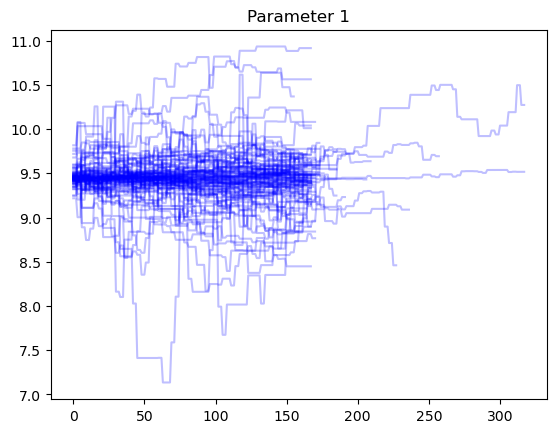

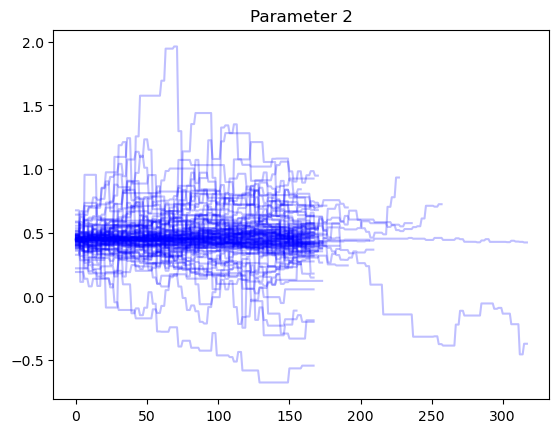

In [13]:
for p in range(n_params):
    for acceptance, ess, n_particles, chain in zip(ACCEPTANCE_L, ESS_L, N_PARTICLES_L, PARAM_CHAINS):
        if acceptance > 0.5:
            plt.plot(chain[:, p], alpha=0.25, c='b')
    plt.title('Parameter {}'.format(p))
    plt.show()

1289it [00:00, 3800.05it/s]


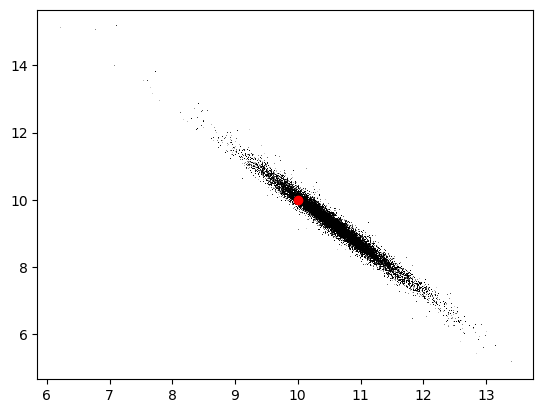

In [3]:
warmup = 10
for i, chain in tqdm(enumerate(PARAM_CHAINS)):
    plt.plot(chain[warmup:, 0], chain[warmup:, 1],  ',k', alpha=0.1)

plt.plot(*ALPHAS, 'ro')

34it [00:00, 2030.82it/s]


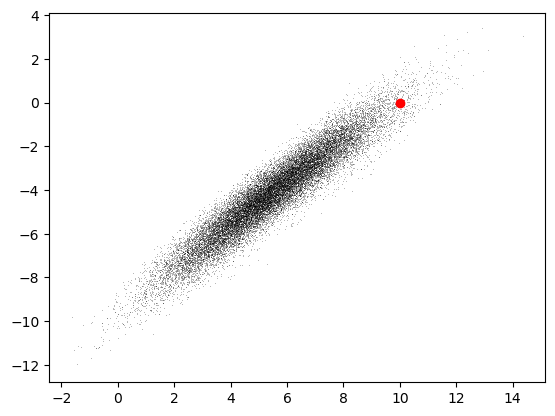

In [4]:
warmup = 10
for i, chain in tqdm(enumerate(PARAM_CHAINS)):
    plt.plot(chain[warmup:, 0], chain[warmup:, 2],  ',k', alpha=0.1)

plt.plot(ALPHAS[0],[0], 'ro')

34it [00:00, 2340.61it/s]


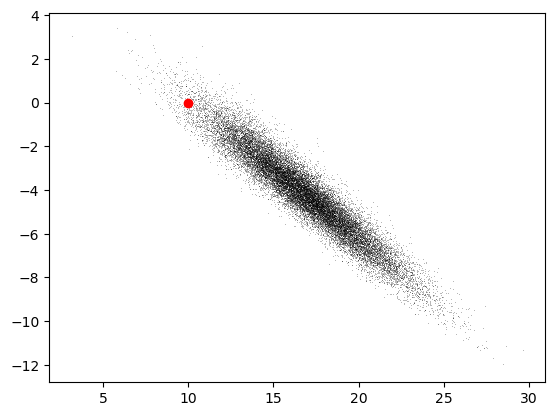

In [5]:
warmup = 10
for i, chain in tqdm(enumerate(PARAM_CHAINS)):
    plt.plot(chain[warmup:, 1], chain[warmup:, 2],  ',k', alpha=0.1)

plt.plot(ALPHAS[1], [0], 'ro')

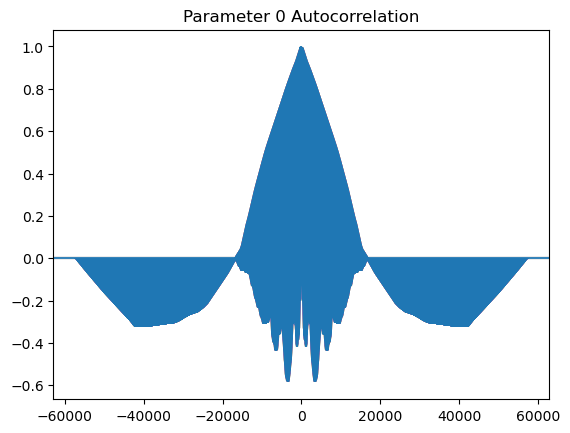

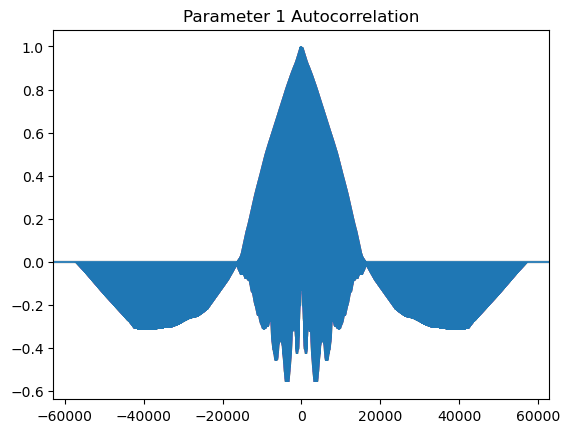

KeyboardInterrupt: 

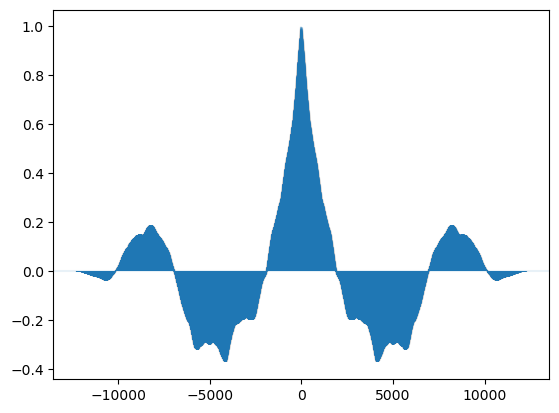

In [5]:
for p in range(n_params):
    for chain in PARAM_CHAINS[:20]:
        chain_mean = np.mean(chain[:, p])
        lag = chain.shape[0] - 1
        plt.acorr(chain[:, p] - chain_mean, alpha=0.1, normed=True, maxlags=lag)
    plt.title('Parameter {} Autocorrelation'.format(p))
    plt.show()

In [7]:
n_phis = 400
phi = np.linspace(0, 2 * np.pi, n_phis)
TORQUES = []

for chain in tqdm(PARAM_CHAINS):
    n_samples = chain.shape[0]
    for s in range(n_samples):
        TORQUES.append(TORQUE(phi, chain[s, :]))

TORQUES = np.array(TORQUES)

Tmax = TORQUES.max()
Tmin = TORQUES.min()
bins = np.linspace(Tmin, Tmax, n_phis)

extent = [0, 2 * np.pi, Tmin, Tmax]
def hist1d(x):
    hist = np.histogram(x, bins=bins, density=True)[0]
    return hist / hist.max()

density = np.apply_along_axis(hist1d, axis=0, arr=TORQUES)

100%|██████████| 34/34 [00:00<00:00, 60.54it/s]


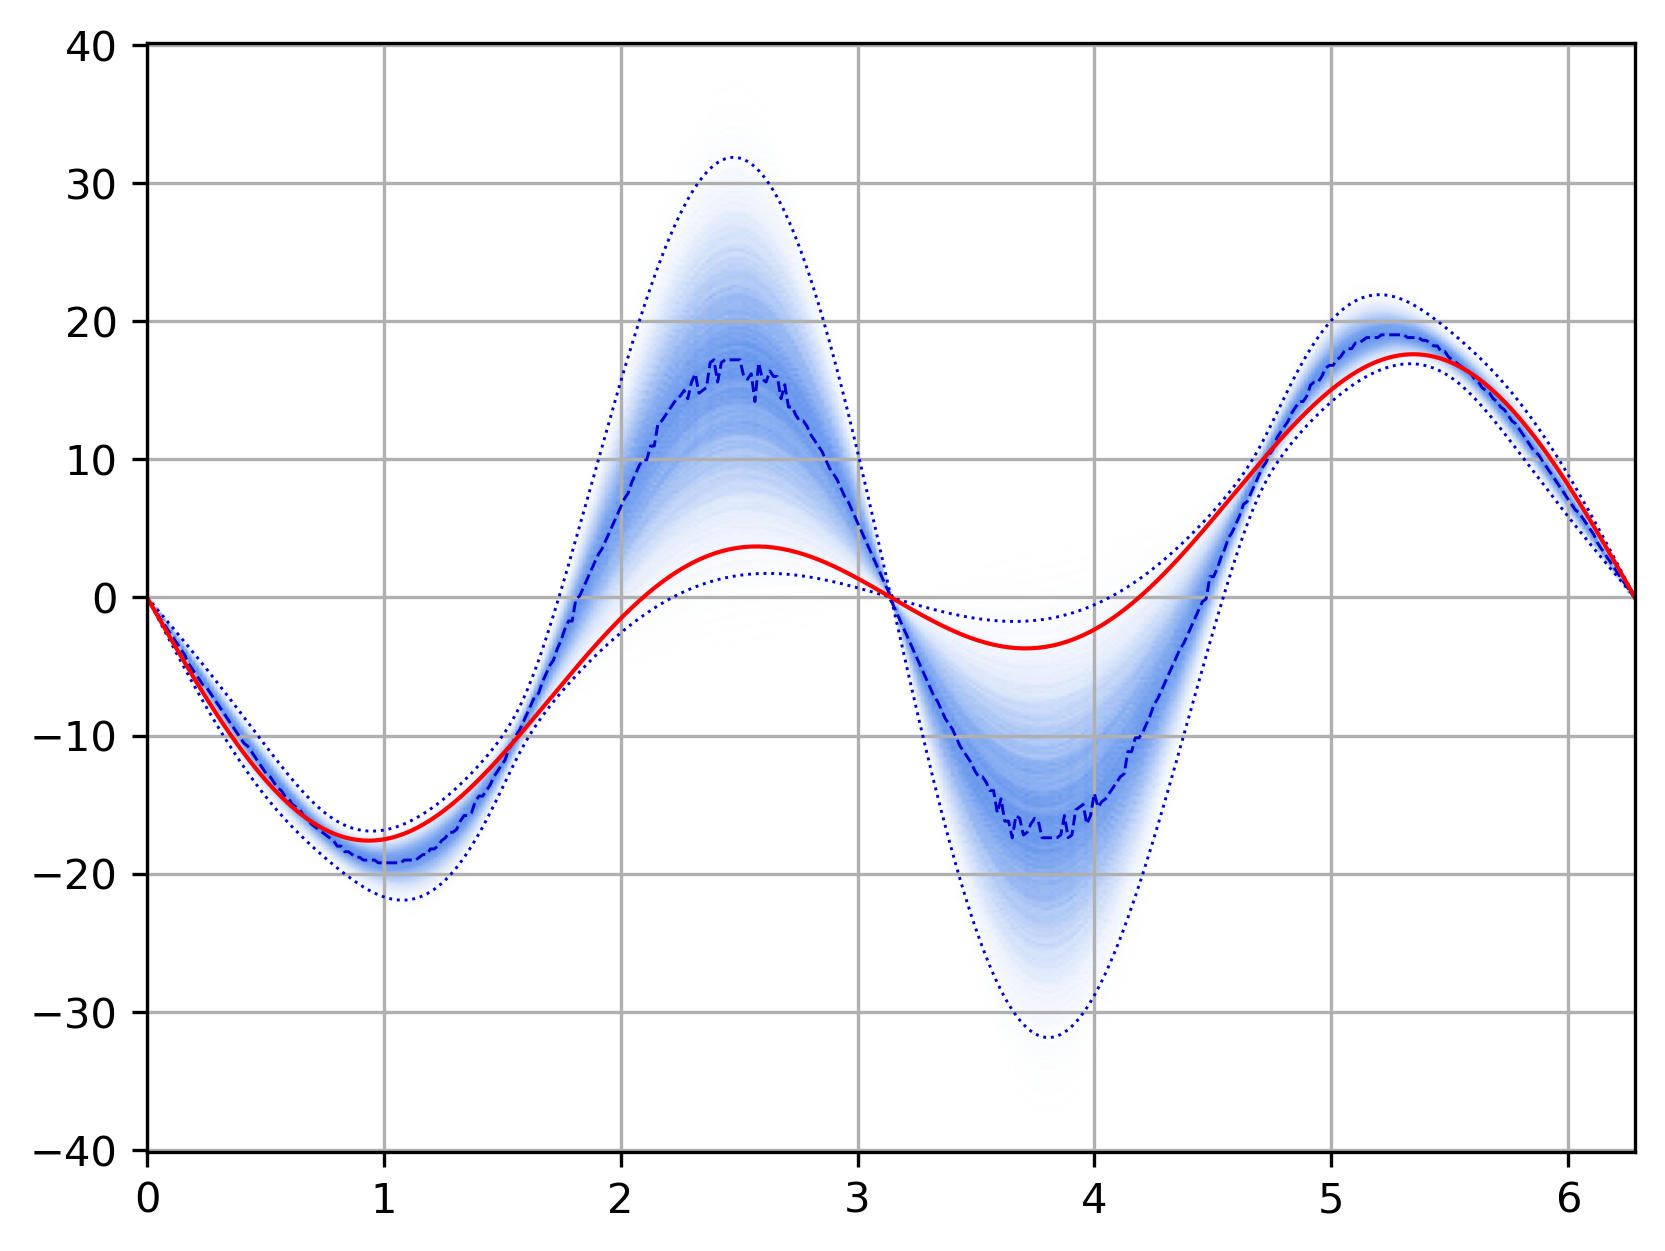

In [8]:
plt.figure(dpi=300)
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white","cornflowerblue"])
plt.imshow(density, extent=extent, aspect='auto', origin='lower', cmap=cmap)

torque_mean = np.mean(TORQUES, axis=0)
torque_mode = bins[np.argmax(density, axis=0)]
torque_std = np.std(TORQUES, axis=0)

torque_true = TORQUE(phi, ALPHAS)


col='mediumblue'
qtil = 2.575829
plt.plot(phi, torque_mean - qtil*torque_std, ':', lw=0.7, c=col)
plt.plot(phi, torque_mean + qtil*torque_std, ':', lw=0.7, c=col)
plt.plot(phi, torque_mode, '--', lw=0.7, alpha=1, c=col)
plt.plot(phi, torque_true, '-', lw=1, alpha=1, c='r')
plt.grid()

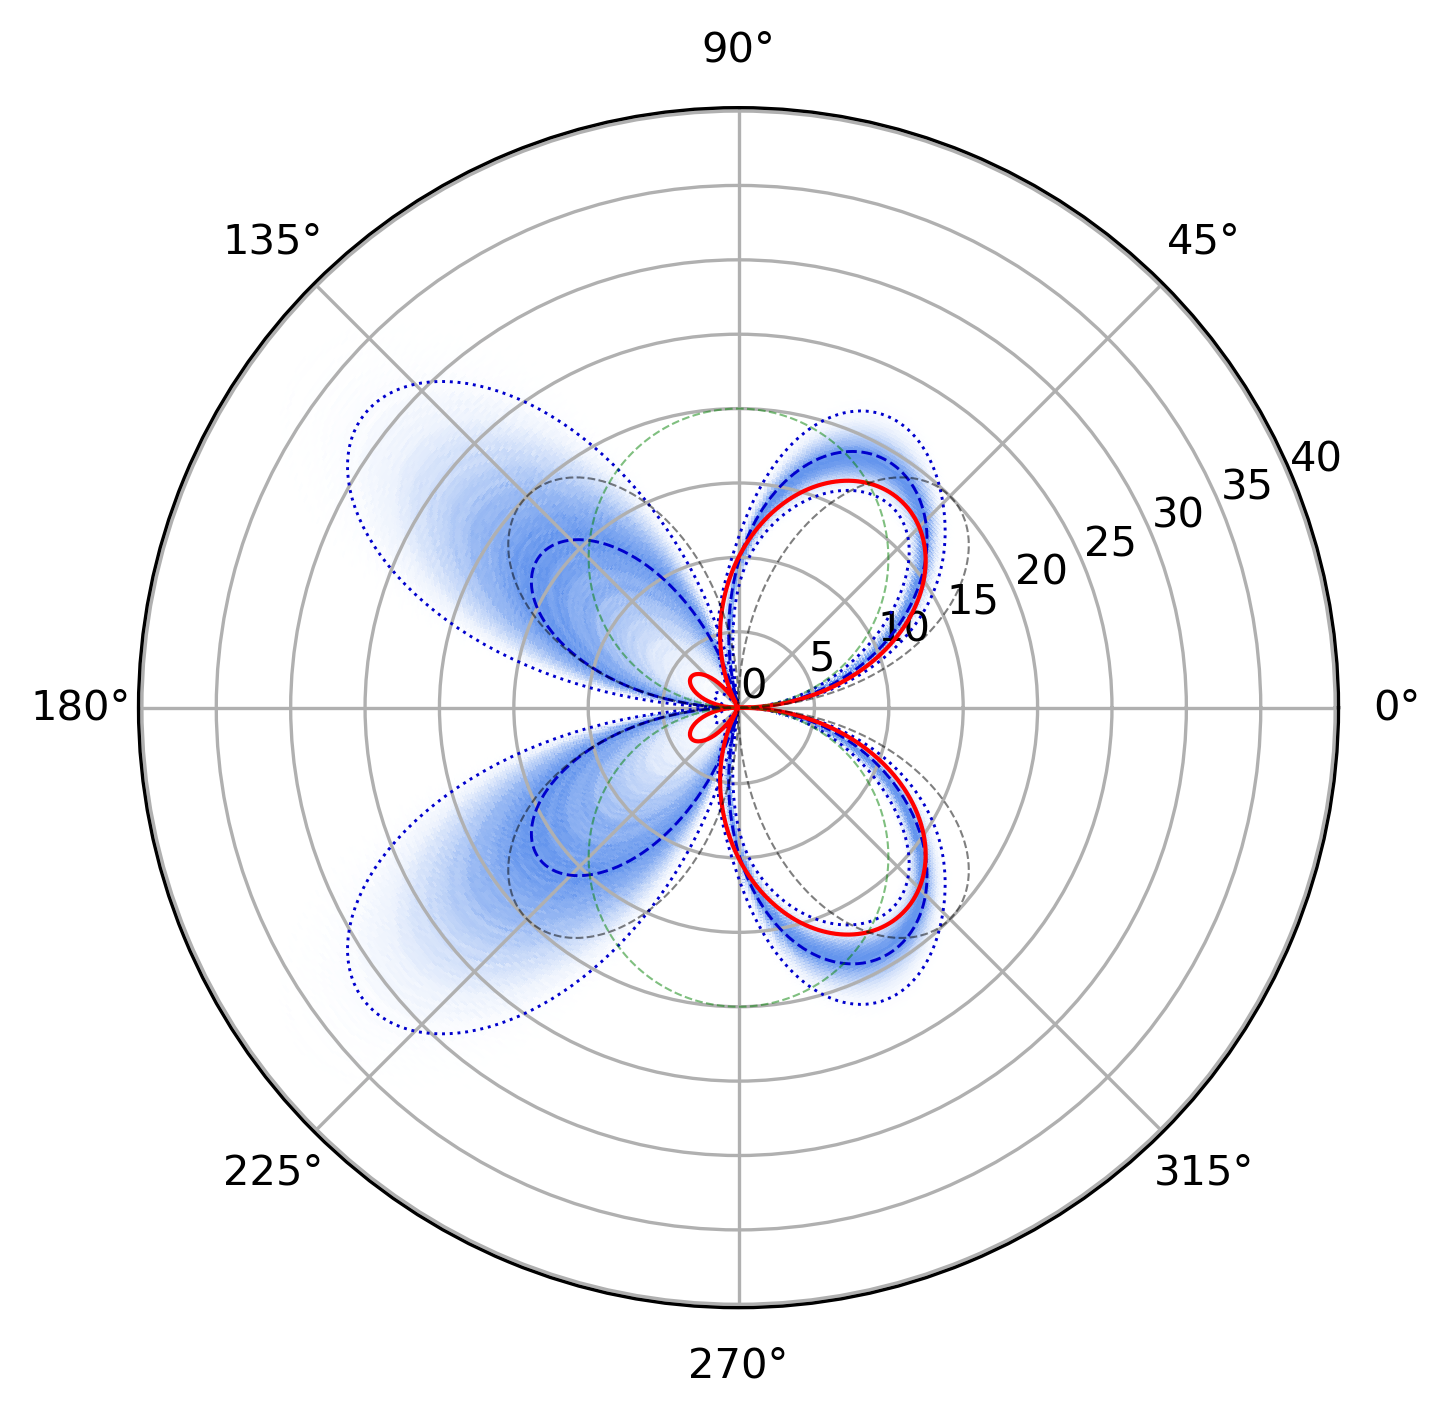

In [9]:
density_mirrored = density + np.flipud(density)
density_mirrored /= density_mirrored.max(axis=0)
density_mirrored = density_mirrored[n_phis // 2:, :]
extent_mirrored = [0, 2 * np.pi, 0, Tmax]
radii = np.linspace(0, Tmax, n_phis//2-1)
fig = plt.figure(figsize=[5,5], dpi=300)
ax = fig.add_axes([0.1,0.1,0.8,0.8], polar=True)
ax.pcolormesh(phi,radii,density_mirrored, edgecolors='face', cmap=cmap)
plt.plot(phi, np.abs(torque_mean - qtil*torque_std), ':', lw=0.7, c=col)
plt.plot(phi, np.abs(torque_mean + qtil*torque_std), ':', lw=0.7, c=col)
plt.plot(phi, np.abs(torque_mean), '--', lw=0.7, alpha=1, c=col)
plt.plot(phi, np.abs(torque_true), '-', lw=1, alpha=1, c='r')

torque_mode_1 = TORQUE(phi, np.atleast_2d([20.]))
plt.plot(phi, np.abs(torque_mode_1), '--', lw=0.5, alpha=0.5, c='g')
torque_mode_2 = TORQUE(phi, np.atleast_2d([0., 20.]).T)
plt.plot(phi, np.abs(torque_mode_2), '--', lw=0.5, alpha=0.5, c='k')

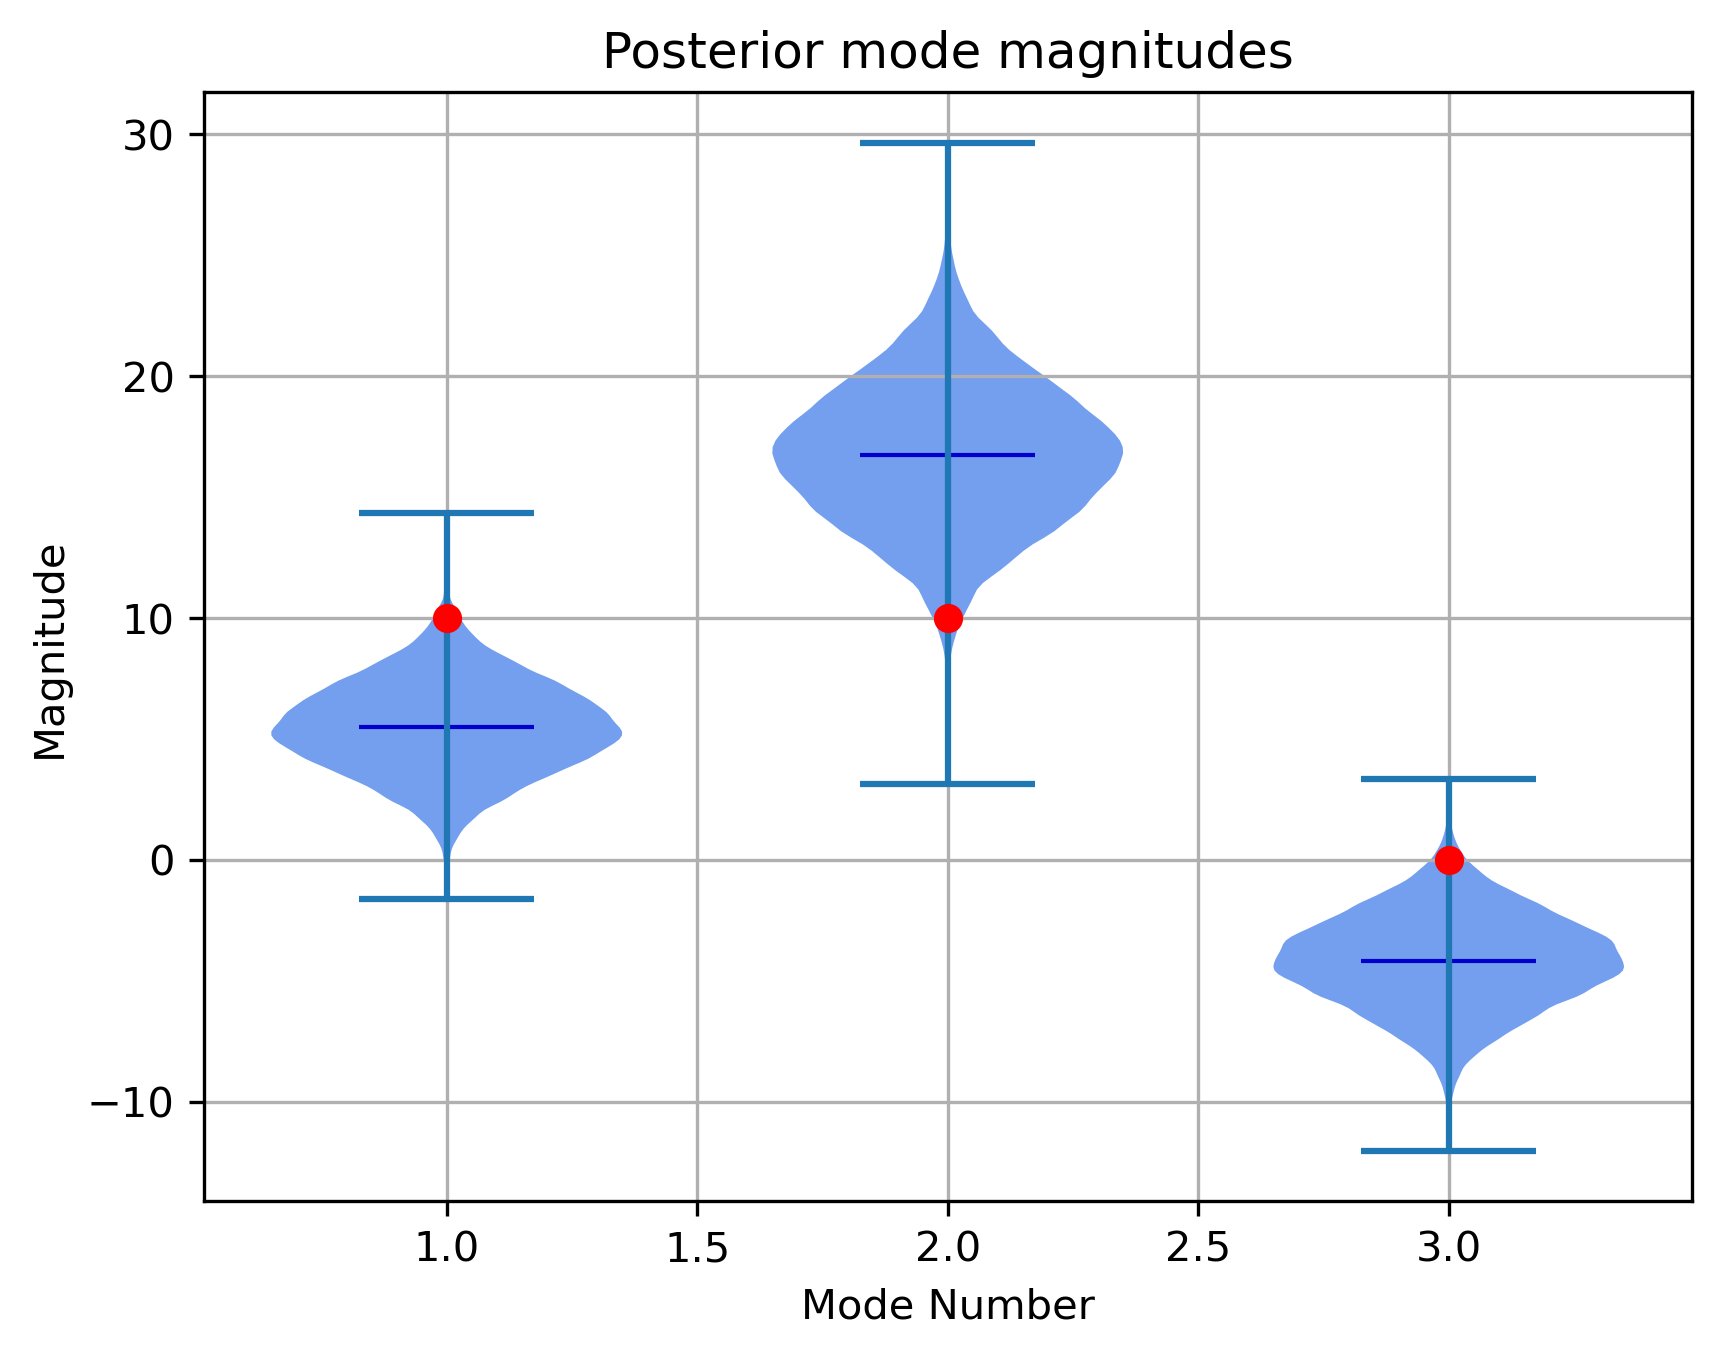

In [10]:
# concatenate all parameters for all chains
all_samples = np.concatenate(PARAM_CHAINS, axis=0)

plt.figure(dpi=300)
viol = plt.violinplot(all_samples, showextrema=True, showmeans=True, widths=0.7)
for body in viol['bodies']:
    body.set_alpha(0.9)
    body.set_facecolor('cornflowerblue')
viol['cmeans'].set_linewidth(1)
viol['cmeans'].set_color('mediumblue')
 
# pad alphas to n_params with zeros
ALPHAS_padded = np.zeros(n_params)
ALPHAS_padded[:2] = ALPHAS
plt.plot(np.arange(1, n_params + 1), ALPHAS_padded, 'ro')
plt.title("Posterior mode magnitudes")
plt.xlabel("Mode Number")
plt.ylabel("Magnitude")
plt.grid()